# Mock globular clusters for NGC 1399 (HUB26)

Builds a MUSE (`MUSE_HUB26`) mock datacube containing **only globular clusters** (GCs):
the NIHAO star particles are replaced by `particlenumber` mock GCs with random ages,
metallicities, masses, positions and velocities, placed at the redshift of NGC 1399.
The cube is computed with the `calc_ifu_no_rot` pipeline (PSF + LSF + noise), converted to flux and stored as FITS.

In [1]:
# Parameters
galaxy_id = "g8.26e11"
component_str = "None"  # "None" -> all components, otherwise e.g. "ThinDisk"
split_file = "./data/gsf/g8.13e11.01024.halo_1.align_with_star.star.gmm_on_jzjcjpjcexyz.scikit_gmm_full_4clusters_white.decontaminated.dat"

output_dir = "./output/ngc1399/no_psf_no_noise"
pipeline_config = "calc_ifu_no_rot_no_psf_no_noise"
redshift = 0.004753 #ngc1399

# Mock GC population
particlenumber = 200
log_mass_mean, log_mass_std = 5.046, 0.588  # log10(M/Msun)

In [2]:
#NBVAL_SKIP
import os

# Pick a free GPU (must happen before JAX initialises its backend)
#from autocvd import autocvd
#autocvd(num_gpus=1)

os.environ["SPS_HOME"] = "/home/annalena_data/sps_fsps"
os.makedirs(output_dir, exist_ok=True)

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from rubix.core.pipeline import RubixPipeline
from rubix.core.fits import store_fits
from rubix.cosmology import PLANCK15
from rubix.spectra.ifu import convert_luminoisty_to_flux

print(jax.devices())

2026-11-20 14:15:22,264 - rubix - INFO - 
   ___  __  _____  _____  __
  / _ \/ / / / _ )/  _/ |/_/
 / , _/ /_/ / _  |/ /_>  <
/_/|_|\____/____/___/_/|_|


2026-11-20 14:15:22,265 - rubix - INFO - Rubix version: 0.0.5.post22+g6b74c2ab7
2026-11-20 14:15:22,266 - rubix - INFO - JAX version: 0.10.2
2026-11-20 14:15:22,266 - rubix - INFO - Running on [CpuDevice(id=0)] devices
2026-11-20 14:15:22,267 - rubix - WARNING - python-fsps is not installed. Install it via `pip install fsps` and see https://dfm.io/python-fsps/current/installation/ for details, including required environment variables.


[CpuDevice(id=0)]


### Reference: EMILES (BaSTI, safe) template grid

- **age [Gyr]:** 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0
- **metallicity Z:** 0.0001, 0.0003, 0.0006, 0.001, 0.002, 0.004, 0.008, 0.01, 0.0198, 0.024, 0.03, 0.04

## Step 1: Config

In [3]:
#NBVAL_SKIP
component = None if component_str is None or component_str.strip() in ("", "None") else component_str

config_NIHAO = {
    "pipeline": {"name": pipeline_config},
    "logger": {
        "log_level": "DEBUG",
        "log_file_path": None,
        "format": "%(asctime)s - %(name)s - %(levelname)s - %(message)s",
    },
    "data": {
        "name": "NihaoHandler",
        "args": {
            "particle_type": ["stars"],
            "save_data_path": "data",
            "snapshot": "1024",
        },
        "load_galaxy_args": {"reuse": True, "id": galaxy_id},
        "subset": {"use_subset": False, "subset_size": 5},
    },
    "simulation": {
        "name": "NIHAO",
        "args": {
            "path": f"/home/_data/nihao/nihao_classic/{galaxy_id}/{galaxy_id}.01024",
            "halo_path": f"/home/_data/nihao/nihao_classic/{galaxy_id}/{galaxy_id}.01024.z0.000.AHF_halos",
            "halo_id": 0,
        },
    },
    "output_path": "output",
    "telescope": {
        "name": "MUSE_HUB26",
        "psf": {"name": "gaussian", "size": 100, "sigma": 2.25},
        "lsf": {"sigma": 1.0},
        "noise": {"signal_to_noise": 3, "s2n_magnitude": 24, "noise_distribution": "normal"},
    },
    "cosmology": {"name": "PLANCK15"},
    "galaxy": {
        "dist_z": redshift,
        "rotation": {"type": "matrix"},
        "component": component,
        "component_file": split_file,
    },
    "ssp": {
        "template": {"name": "EMILES_BASTI_BASE_CH_FITS_safe"},
        "dust": {
            "extinction_model": "Cardelli89",
            "dust_to_gas_ratio": 0.003,
            "dust_to_metals_ratio": 0.4,
            "dust_grain_density": 3.5,
            "Rv": 3.1,
        },
    },
}

## Step 2: Load the NIHAO galaxy

In [4]:
#NBVAL_SKIP
pipe = RubixPipeline(config_NIHAO)
inputdata = pipe.prepare_data()

2026-11-20 14:15:25,296 - rubix - INFO - No telescope config provided, falling back to /home/annalena/.conda/envs/rubix/lib/python3.12/site-packages/rubix/telescope/telescopes.yaml
/home/annalena/.conda/envs/rubix/lib/python3.12/site-packages/rubix/telescope/factory.py:32: UserWarning: No telescope config provided, using default stored in /home/annalena/.conda/envs/rubix/lib/python3.12/site-packages/rubix/telescope/telescopes.yaml
  warnings.warn(
2026-11-20 14:15:26,039 - rubix - INFO - Getting rubix data...
2026-11-20 14:15:26,040 - rubix - INFO - Loading data into input handler
2026-11-20 14:15:26,041 - rubix - INFO - Using PynbodyHandler to load a NIHAO galaxy
2026-11-20 14:15:26,046 - rubix - INFO - Galaxy redshift (dist_z) set to: 0.004753
2026-11-20 14:15:26,082 - rubix - INFO - Simulation snapshot loaded from halo 0
2026-11-20 14:15:26,253 - rubix - INFO - Halo data loaded.
2026-11-20 14:15:30,285 - rubix - INFO - Rotation matrix calculated and saved to '/notebooks/data/rotatio

Converted to Rubix format!


2026-11-20 14:15:31,711 - rubix - INFO - Data loaded with 739749 star particles and 0 gas particles.
2026-11-20 14:15:31,713 - rubix - INFO - Data preparation completed in 5.67 seconds.


## Step 3: Replace the star particles by mock GCs

For reference, the NIHAO star coordinates span roughly x ∈ [-177, 174], y ∈ [-187, 207], z ∈ [-187, 197];
the mock GCs are placed uniformly within ±1.9 in each coordinate.

In [5]:
#NBVAL_SKIP
# Log-normal GC masses
log_mass = log_mass_mean + log_mass_std * jax.random.normal(jax.random.PRNGKey(325), (particlenumber,))

key = jax.random.PRNGKey(79)
key_age, key_met, _, key_x, key_y, key_z, key_vx, key_vy, key_vz = jax.random.split(key, num=9)

def uniform(k, lo, hi):
    return jax.random.uniform(k, shape=(particlenumber,), minval=lo, maxval=hi)

inputdata.stars.age = uniform(key_age, 10.0, 14.0)  # Gyr
inputdata.stars.metallicity = uniform(key_met, 0.00046, 0.02)
inputdata.stars.mass = 10**log_mass
inputdata.stars.coords = jnp.column_stack([uniform(k, -3.0, 3.0) for k in (key_x, key_y, key_z)])
inputdata.stars.velocity = jnp.column_stack([uniform(k, -100.0, 100.0) for k in (key_vx, key_vy, key_vz)])

# Save the injected GC catalogue
gc_table = jnp.column_stack((
    inputdata.stars.age,
    inputdata.stars.metallicity,
    inputdata.stars.mass,
    inputdata.stars.velocity,
    inputdata.stars.coords,
))
np.savetxt(
    f"{output_dir}/gc_injected_data.txt",
    np.asarray(gc_table),
    header="age metallicity mass vx vy vz cx cy cz",
    fmt="%.6e",
    comments="# ",
)

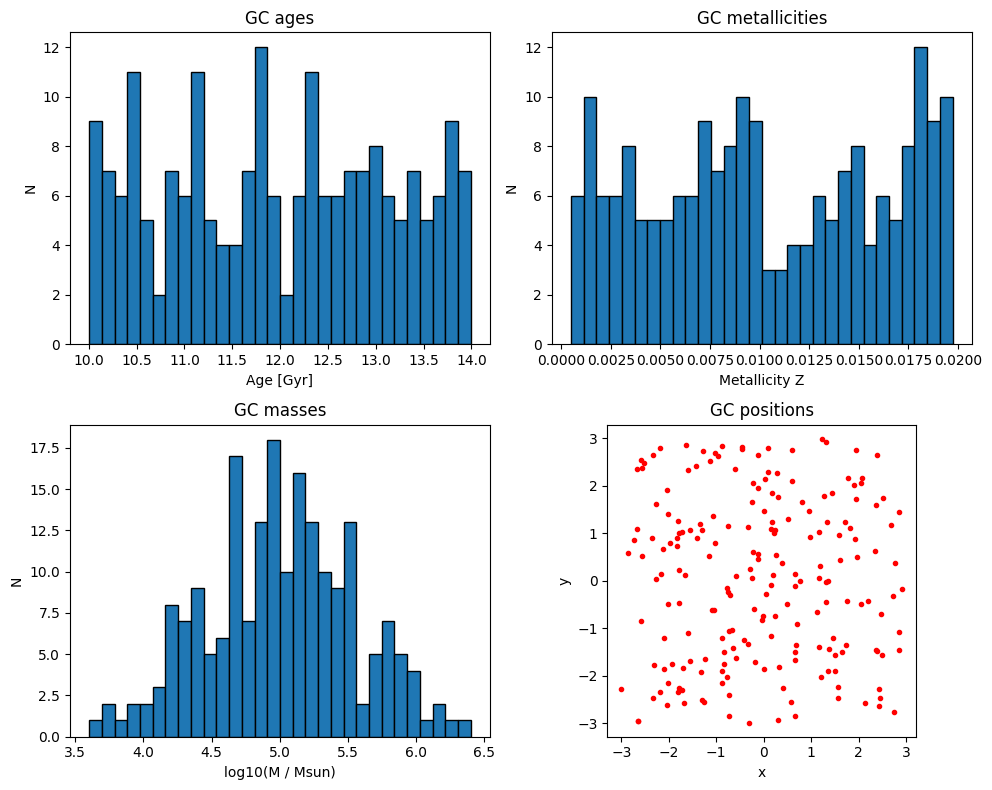

In [6]:
#NBVAL_SKIP
gc = inputdata.stars
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].hist(gc.age, bins=30, edgecolor="black")
axes[0, 0].set(xlabel="Age [Gyr]", ylabel="N", title="GC ages")

axes[0, 1].hist(gc.metallicity, bins=30, edgecolor="black")
axes[0, 1].set(xlabel="Metallicity Z", ylabel="N", title="GC metallicities")

axes[1, 0].hist(np.log10(gc.mass), bins=30, edgecolor="black")
axes[1, 0].set(xlabel="log10(M / Msun)", ylabel="N", title="GC masses")

axes[1, 1].plot(gc.coords[:, 0], gc.coords[:, 1], "ro", markersize=3)
axes[1, 1].set(xlabel="x", ylabel="y", title="GC positions", aspect="equal")

fig.tight_layout()
fig.savefig(f"{output_dir}/gc_properties_{galaxy_id}_{component}.jpeg")
plt.show()

## Step 4: Run the pipeline

In [7]:
#NBVAL_SKIP
rubixdata = pipe.run_sharded(inputdata)

2026-11-20 14:15:33,487 - rubix - INFO - Setting up the pipeline...
2026-11-20 14:15:33,488 - rubix - DEBUG - Pipeline Configuration: {'Transformers': {'spaxel_assignment': {'name': 'spaxel_assignment', 'depends_on': None, 'args': [], 'kwargs': {}}, 'calculate_datacube_particlewise': {'name': 'calculate_datacube_particlewise', 'depends_on': 'spaxel_assignment', 'args': [], 'kwargs': {}}, 'convolve_lsf': {'name': 'convolve_lsf', 'depends_on': 'calculate_datacube_particlewise', 'args': [], 'kwargs': {}}}}
2026-11-20 14:15:33,489 - rubix - DEBUG - Roataion Type found: matrix
2026-11-20 14:15:33,491 - rubix - INFO - Calculating spatial bin edges...
2026-11-20 14:15:33,492 - rubix - INFO - No telescope config provided, falling back to /home/annalena/.conda/envs/rubix/lib/python3.12/site-packages/rubix/telescope/telescopes.yaml
/home/annalena/.conda/envs/rubix/lib/python3.12/site-packages/rubix/telescope/factory.py:32: UserWarning: No telescope config provided, using default stored in /home/

### Convert luminosity to flux and store as FITS

The cube is stored in units of 1e-20 erg/s/cm²/Å.

In [8]:
#NBVAL_SKIP
observation_z = config_NIHAO["galaxy"]["dist_z"]
observation_lum_dist = PLANCK15.luminosity_distance_to_z(observation_z)
pixel_size = 1.0  # arcsec^2

fluxcube = convert_luminoisty_to_flux(rubixdata, observation_lum_dist, observation_z, pixel_size)
rubixdata = fluxcube / 1e-20

store_fits(config_NIHAO, rubixdata, f"{output_dir}/")

2026-11-20 14:15:44,655 - rubix - INFO - No telescope config provided, falling back to /home/annalena/.conda/envs/rubix/lib/python3.12/site-packages/rubix/telescope/telescopes.yaml
2026-11-20 14:15:50,944 - rubix - INFO - Datacube saved to ./output/ngc1399/no_psf_no_noise/NIHAO_idg8.26e11_snap1024_subsetFalse.fits


## Step 5: Inspect the mock datacube

Image summed over 4000–8000 Å and spectra of the full cube and of a few spaxels.

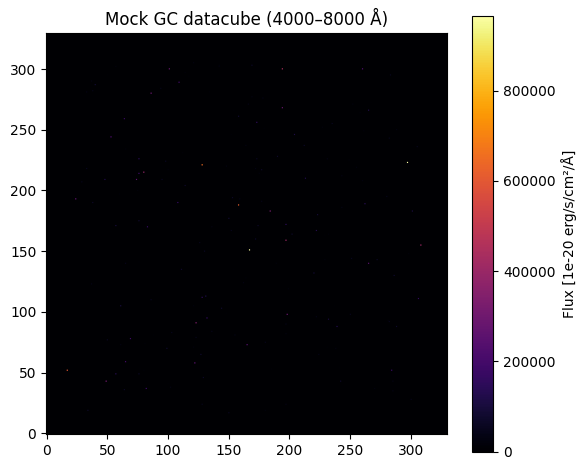

In [9]:
#NBVAL_SKIP
wave = pipe.telescope.wave_seq
visible = (wave >= 4000) & (wave <= 8000)
image = np.asarray(jnp.sum(rubixdata[:, :, visible], axis=2), dtype=np.float32)

plt.figure(figsize=(6, 5))
plt.imshow(image, origin="lower", cmap="inferno")
plt.title("Mock GC datacube (4000–8000 Å)")
plt.colorbar(label="Flux [1e-20 erg/s/cm²/Å]")
plt.tight_layout()
plt.savefig(f"{output_dir}/image_{galaxy_id}_{component}.jpeg")
plt.show()

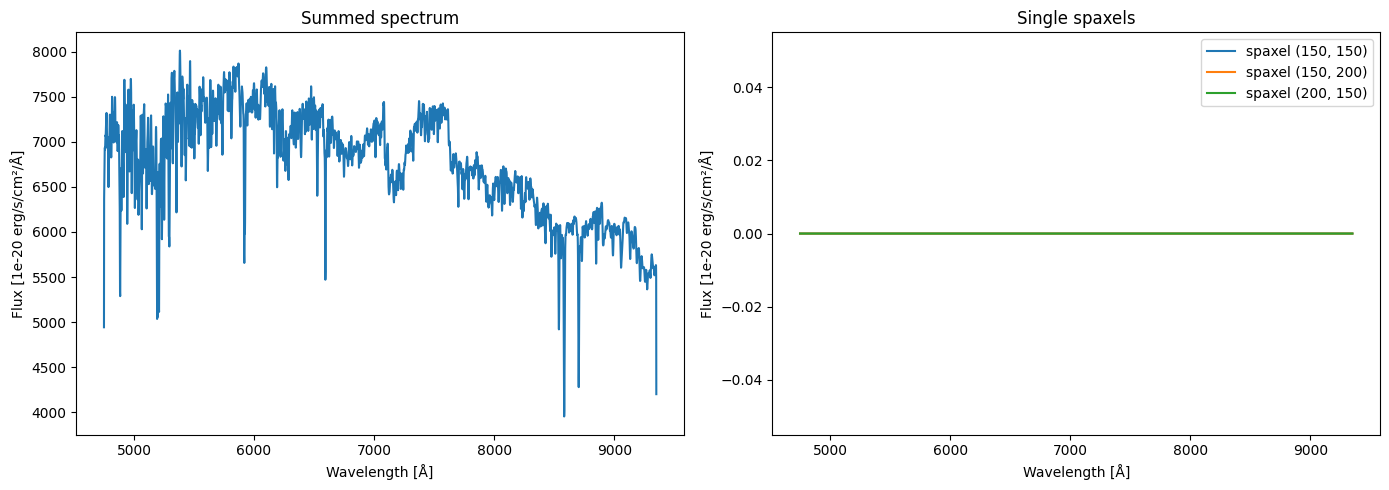

In [10]:
#NBVAL_SKIP
fig, (ax_sum, ax_spx) = plt.subplots(1, 2, figsize=(14, 5))

ax_sum.plot(wave, jnp.sum(rubixdata, axis=(0, 1)))
ax_sum.set(title="Summed spectrum", xlabel="Wavelength [Å]", ylabel="Flux [1e-20 erg/s/cm²/Å]")

for i, j in [(150, 150), (150, 200), (200, 150)]:
    ax_spx.plot(wave, rubixdata[i, j, :], label=f"spaxel ({i}, {j})")
ax_spx.set(title="Single spaxels", xlabel="Wavelength [Å]", ylabel="Flux [1e-20 erg/s/cm²/Å]")
ax_spx.legend()

fig.tight_layout()
fig.savefig(f"{output_dir}/spectra_{galaxy_id}_{component}.jpeg")
plt.show()